<a href="https://colab.research.google.com/github/mahmud1137/Spam_Mail_Detection/blob/main/experiment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import string
import pandas as pd
import re
import seaborn as sns
import matplotlib.pyplot as plt
from imblearn.over_sampling import SMOTE
from nltk.corpus import stopwords
from nltk import pos_tag
from nltk.corpus import wordnet
from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [2]:
import nltk
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('averaged_perceptron_tagger_eng')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /root/nltk_data...
[nltk_data]   Unzipping taggers/averaged_perceptron_tagger_eng.zip.


True

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
df = pd.read_csv('/content/drive/My Drive/Ostad/dataset.csv')
print(df.head())
print(df.isnull().sum())


   Unnamed: 0 label                                               text  \
0         605   ham  Subject: enron methanol ; meter # : 988291\r\n...   
1        2349   ham  Subject: hpl nom for january 9 , 2001\r\n( see...   
2        3624   ham  Subject: neon retreat\r\nho ho ho , we ' re ar...   
3        4685  spam  Subject: photoshop , windows , office . cheap ...   
4        2030   ham  Subject: re : indian springs\r\nthis deal is t...   

   label_num  
0          0  
1          0  
2          0  
3          1  
4          0  
Unnamed: 0    0
label         0
text          0
label_num     0
dtype: int64


In [5]:
df = df.drop(columns=["Unnamed: 0", "label_num"], axis=1)
print(df.head())

  label                                               text
0   ham  Subject: enron methanol ; meter # : 988291\r\n...
1   ham  Subject: hpl nom for january 9 , 2001\r\n( see...
2   ham  Subject: neon retreat\r\nho ho ho , we ' re ar...
3  spam  Subject: photoshop , windows , office . cheap ...
4   ham  Subject: re : indian springs\r\nthis deal is t...


In [6]:
df["clean_text"] = df["text"].str.lower()
df.sample(frac=1).head()

,label,text,clean_text
1295,ham,Subject: buyer vs . seller on intercompany dea...,subject: buyer vs . seller on intercompany dea...
1044,spam,Subject: \r\nreceived : from 182 . 152 . 35 . ...,subject: \r\nreceived : from 182 . 152 . 35 . ...
1032,spam,"Subject: fwd : hi paliourg , like to watch rea...","subject: fwd : hi paliourg , like to watch rea..."
4325,spam,Subject: windows xp suites 242296\r\nspecials ...,subject: windows xp suites 242296\r\nspecials ...
3492,spam,Subject: guys need this 3 dq\r\nci - ialis sof...,subject: guys need this 3 dq\r\nci - ialis sof...


In [7]:
string.punctuation

'!"#$%&\'()*+,-./:;<=>?@[\\]^_`{|}~'

In [8]:
def remove_punctuation(text):
  punctuation = string.punctuation
  return text.translate(str.maketrans("", "", punctuation))

In [9]:
df["clean_text"] = df["clean_text"].apply(lambda x: remove_punctuation(x))
df.head()

,label,text,clean_text
0,ham,Subject: enron methanol ; meter # : 988291\r\n...,subject enron methanol meter 988291\r\nthis...
1,ham,"Subject: hpl nom for january 9 , 2001\r\n( see...",subject hpl nom for january 9 2001\r\n see at...
2,ham,"Subject: neon retreat\r\nho ho ho , we ' re ar...",subject neon retreat\r\nho ho ho we re aroun...
3,spam,"Subject: photoshop , windows , office . cheap ...",subject photoshop windows office cheap mai...
4,ham,Subject: re : indian springs\r\nthis deal is t...,subject re indian springs\r\nthis deal is to ...


In [10]:
STOPWORDS = set(stopwords.words("english"))
def remove_stopwords(text):
  return " ".join([word for word in str(text).split() if word not in STOPWORDS])


In [11]:
df["clean_text"] = df["clean_text"].apply(lambda x: remove_stopwords(x))
df.head()

,label,text,clean_text
0,ham,Subject: enron methanol ; meter # : 988291\r\n...,subject enron methanol meter 988291 follow not...
1,ham,"Subject: hpl nom for january 9 , 2001\r\n( see...",subject hpl nom january 9 2001 see attached fi...
2,ham,"Subject: neon retreat\r\nho ho ho , we ' re ar...",subject neon retreat ho ho ho around wonderful...
3,spam,"Subject: photoshop , windows , office . cheap ...",subject photoshop windows office cheap main tr...
4,ham,Subject: re : indian springs\r\nthis deal is t...,subject indian springs deal book teco pvr reve...


In [12]:
def remove_numbers(text):
  return re.sub(r"\d+", "", text)

In [13]:
def remove_urls(text):
  return re.sub(r'http\S+|www\S+|https\S+', ' URL ', text)

In [14]:
df["clean_text"] = df["clean_text"].apply(lambda x: remove_urls(x))
df.head()

,label,text,clean_text
0,ham,Subject: enron methanol ; meter # : 988291\r\n...,subject enron methanol meter 988291 follow not...
1,ham,"Subject: hpl nom for january 9 , 2001\r\n( see...",subject hpl nom january 9 2001 see attached fi...
2,ham,"Subject: neon retreat\r\nho ho ho , we ' re ar...",subject neon retreat ho ho ho around wonderful...
3,spam,"Subject: photoshop , windows , office . cheap ...",subject photoshop windows office cheap main tr...
4,ham,Subject: re : indian springs\r\nthis deal is t...,subject indian springs deal book teco pvr reve...


In [15]:
def remove_emails(text):
  return re.sub(r'\S+@\S+', ' EMAIL ', text)

In [16]:
df["clean_text"] = df["clean_text"].apply(lambda x: remove_emails(x))
df.head()

,label,text,clean_text
0,ham,Subject: enron methanol ; meter # : 988291\r\n...,subject enron methanol meter 988291 follow not...
1,ham,"Subject: hpl nom for january 9 , 2001\r\n( see...",subject hpl nom january 9 2001 see attached fi...
2,ham,"Subject: neon retreat\r\nho ho ho , we ' re ar...",subject neon retreat ho ho ho around wonderful...
3,spam,"Subject: photoshop , windows , office . cheap ...",subject photoshop windows office cheap main tr...
4,ham,Subject: re : indian springs\r\nthis deal is t...,subject indian springs deal book teco pvr reve...


In [17]:
def remove_spl_chars(text):
  return re.sub("[^a-zA-Z0-9]", ' ', text)

In [18]:
df["clean_text"] = df["clean_text"].apply(lambda x: remove_spl_chars(x))
df.head()

,label,text,clean_text
0,ham,Subject: enron methanol ; meter # : 988291\r\n...,subject enron methanol meter 988291 follow not...
1,ham,"Subject: hpl nom for january 9 , 2001\r\n( see...",subject hpl nom january 9 2001 see attached fi...
2,ham,"Subject: neon retreat\r\nho ho ho , we ' re ar...",subject neon retreat ho ho ho around wonderful...
3,spam,"Subject: photoshop , windows , office . cheap ...",subject photoshop windows office cheap main tr...
4,ham,Subject: re : indian springs\r\nthis deal is t...,subject indian springs deal book teco pvr reve...


In [19]:
lemmatizer = WordNetLemmatizer()
wordnet_map = {"N":wordnet.NOUN, "V":wordnet.VERB, "J":wordnet.ADJ, "R":wordnet.ADV}

def lemmatizer_words(text):
  pos_text = pos_tag(text.split())
  return " ".join([lemmatizer.lemmatize(word, wordnet_map.get(pos[0], wordnet.NOUN)) for word, pos in pos_text])

In [20]:
df['lemmatized_text'] = df["clean_text"].apply(lambda x: lemmatizer_words(x))
df.head()

,label,text,clean_text,lemmatized_text
0,ham,Subject: enron methanol ; meter # : 988291\r\n...,subject enron methanol meter 988291 follow not...,subject enron methanol meter 988291 follow not...
1,ham,"Subject: hpl nom for january 9 , 2001\r\n( see...",subject hpl nom january 9 2001 see attached fi...,subject hpl nom january 9 2001 see attach file...
2,ham,"Subject: neon retreat\r\nho ho ho , we ' re ar...",subject neon retreat ho ho ho around wonderful...,subject neon retreat ho ho ho around wonderful...
3,spam,"Subject: photoshop , windows , office . cheap ...",subject photoshop windows office cheap main tr...,subject photoshop windows office cheap main tr...
4,ham,Subject: re : indian springs\r\nthis deal is t...,subject indian springs deal book teco pvr reve...,subject indian spring deal book teco pvr reven...


In [21]:
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(df["label"])
X = df["clean_text"]


label
ham     3672
spam    1499
Name: count, dtype: int64


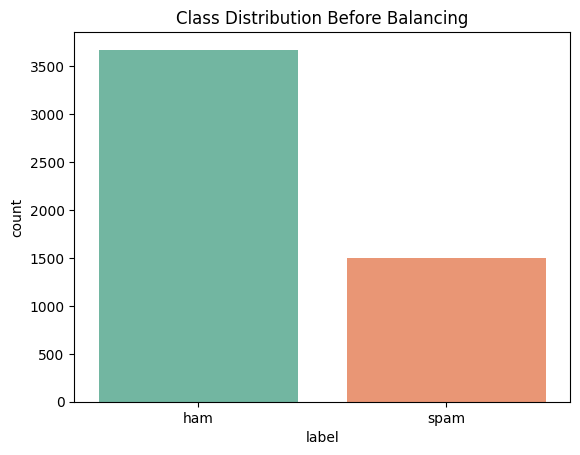

In [22]:
print(df['label'].value_counts())

sns.countplot(x='label', data=df, palette='Set2', hue='label', legend=False)
plt.title("Class Distribution Before Balancing")
plt.show()

In [23]:
X_train_text, X_test_text, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)


In [24]:
tfidf = TfidfVectorizer(
    stop_words="english",
    max_features=5000
)

X_train = tfidf.fit_transform(X_train_text)
X_test = tfidf.transform(X_test_text)

In [25]:
smote = SMOTE(random_state=42)
X_train_balanced, y_train_balanced = smote.fit_resample(
    X_train, y_train
)

print("Training distribution before SMOTE:")
print(pd.Series(y_train).value_counts())

print("\nTraining distribution after SMOTE:")
print(pd.Series(y_train_balanced).value_counts())

print("\nTest distribution (unchanged):")
print(pd.Series(y_test).value_counts())

Training distribution before SMOTE:
0    2937
1    1199
Name: count, dtype: int64

Training distribution after SMOTE:
1    2937
0    2937
Name: count, dtype: int64

Test distribution (unchanged):
0    735
1    300
Name: count, dtype: int64


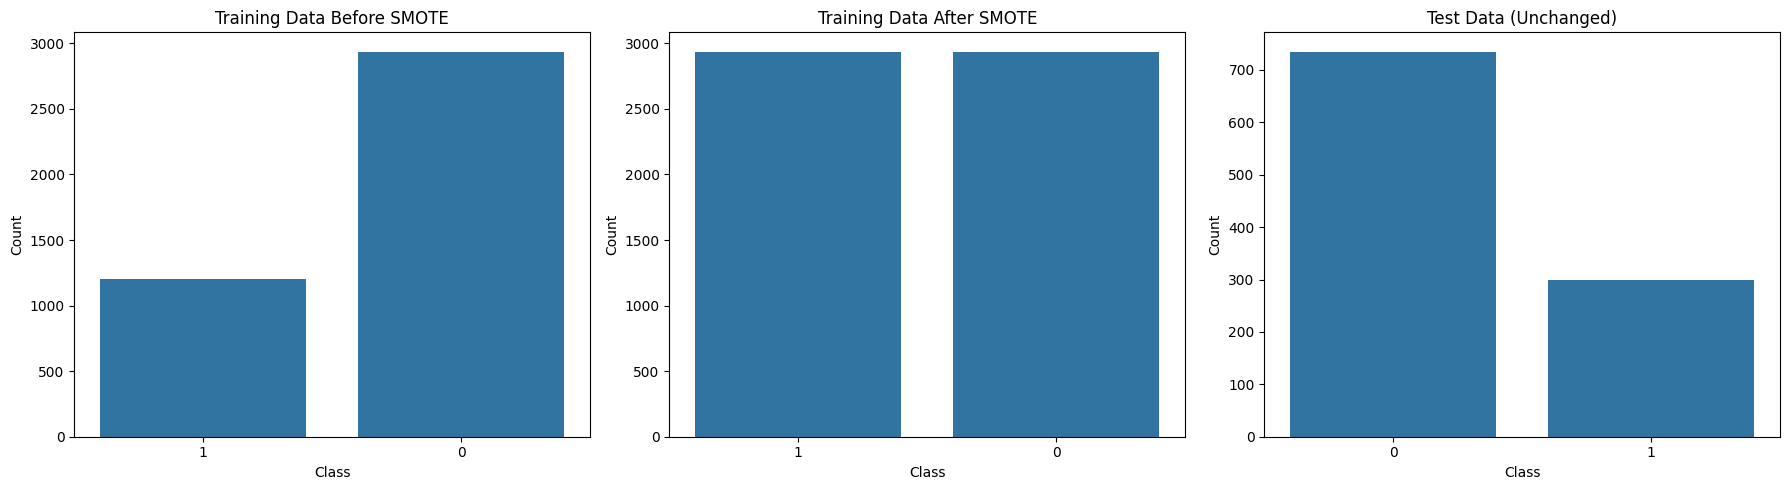

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.countplot(x=pd.Series(y_train).astype(str), ax=axes[0])
axes[0].set_title("Training Data Before SMOTE")
axes[0].set_xlabel("Class")
axes[0].set_ylabel("Count")

sns.countplot(x=pd.Series(y_train_balanced).astype(str), ax=axes[1])
axes[1].set_title("Training Data After SMOTE")
axes[1].set_xlabel("Class")
axes[1].set_ylabel("Count")

sns.countplot(x=pd.Series(y_test).astype(str), ax=axes[2])
axes[2].set_title("Test Data (Unchanged)")
axes[2].set_xlabel("Class")
axes[2].set_ylabel("Count")

plt.tight_layout()
plt.show()

Accuracy: 0.9516908212560387
              precision    recall  f1-score   support

           0       0.97      0.96      0.97       735
           1       0.90      0.93      0.92       300

    accuracy                           0.95      1035
   macro avg       0.94      0.95      0.94      1035
weighted avg       0.95      0.95      0.95      1035

Confusion Matrix:
 [[705  30]
 [ 20 280]]


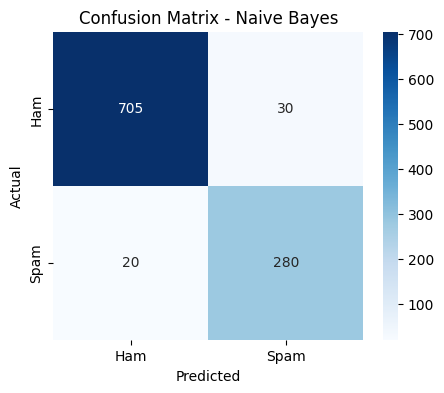

In [27]:
model = MultinomialNB()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:\n", cm)

plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Ham', 'Spam'], yticklabels=['Ham', 'Spam'])
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Confusion Matrix - Naive Bayes')
plt.show()

Accuracy: 0.9864734299516909
              precision    recall  f1-score   support

           0       0.99      0.99      0.99       735
           1       0.97      0.99      0.98       300

    accuracy                           0.99      1035
   macro avg       0.98      0.99      0.98      1035
weighted avg       0.99      0.99      0.99      1035

Confusion Matrix:
 [[725  10]
 [  4 296]]


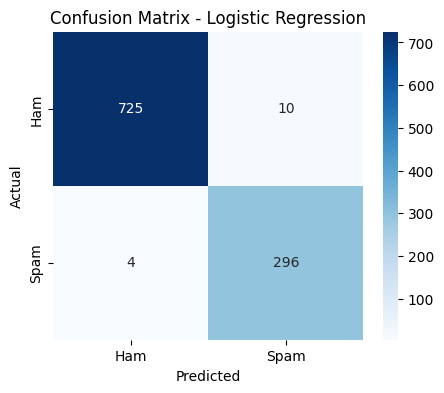

In [28]:
model = LogisticRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:\n", cm)

plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Ham', 'Spam'], yticklabels=['Ham', 'Spam'])
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Confusion Matrix - Logistic Regression')
plt.show()

Accuracy: 0.9835748792270531
              precision    recall  f1-score   support

           0       1.00      0.98      0.99       735
           1       0.95      1.00      0.97       300

    accuracy                           0.98      1035
   macro avg       0.97      0.99      0.98      1035
weighted avg       0.98      0.98      0.98      1035

Confusion Matrix:
 [[719  16]
 [  1 299]]


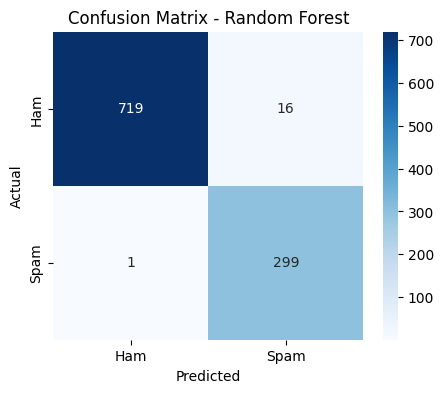

In [29]:
model = RandomForestClassifier()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:\n", cm)

plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Ham', 'Spam'], yticklabels=['Ham', 'Spam'])
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Confusion Matrix - Random Forest')
plt.show()

Accuracy: 0.9864734299516909
              precision    recall  f1-score   support

           0       0.99      0.99      0.99       735
           1       0.98      0.98      0.98       300

    accuracy                           0.99      1035
   macro avg       0.98      0.98      0.98      1035
weighted avg       0.99      0.99      0.99      1035

Confusion Matrix:
 [[728   7]
 [  7 293]]


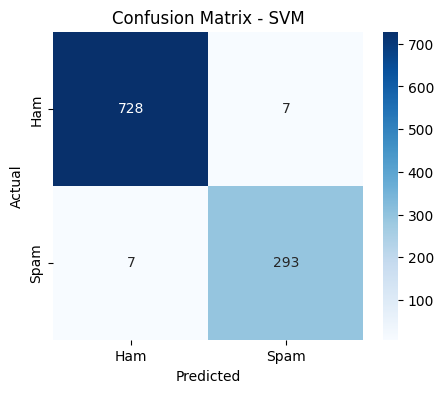

In [30]:
model = LinearSVC()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:\n", cm)

plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Ham', 'Spam'], yticklabels=['Ham', 'Spam'])
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Confusion Matrix - SVM')
plt.show()